# Multimodal AI for medical imaging: hands-on notebook

Companion to the FDP session *Multimodal AI Models for Medical Imaging Analysis*. Three workflows on real, public, de-identified data:

| | Workflow | Data | Model |
|---|---|---|---|
| A | Load and view a DICOM CT study | LIDC-IDRI-0001 (TCIA, CC BY 3.0) | none |
| B | Match an X-ray with descriptions | the same patient's chest X-ray (DICOM), plus Indiana University X-rays (PNG) | BiomedCLIP |
| C | Outline anatomy and a nodule | the same CT | TotalSegmentator, MedSAM |

**Before you start:** run `python download_data.py` once (about 90 MB for workflows A–C; the optional IU X-ray set is 1.4 GB). See `README.md` for setup, runtimes and troubleshooting.

**Privacy.** These datasets were de-identified by their publishers. Hospital DICOM files are not: never upload real patient files to online notebooks or AI services.

**Interpretation.** Every score in this notebook is a research output, not a diagnosis.

In [1]:
# Colab only: fetch the project and data and install what Colab lacks (about 5 minutes).
# In Colab choose Runtime > Change runtime type > GPU first. Elsewhere this cell does nothing.
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.path.exists('download_data.py'):
    if not os.path.exists('multimodal-medical-imaging'):
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/drneelmani/multimodal-medical-imaging.git'], check=True)
    os.chdir('multimodal-medical-imaging/notebook')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pydicom', 'SimpleITK', 'nibabel', 'open_clip_torch', 'TotalSegmentator'], check=True)
    subprocess.run([sys.executable, 'download_data.py'], check=True)
print('Working folder:', os.getcwd())

Working folder: /media/ai-centre-01/VISHNU/LEARNING/NeelSir - PPTs/Multimodal-AI-Models-for-Medical-Imaging-Analysis/notebook


In [2]:
# Setup: libraries and paths. Runs on a GPU if one is available, otherwise on the CPU.
import glob, json, os, time
import numpy as np
import matplotlib.pyplot as plt
import pydicom
import SimpleITK as sitk
import torch

DATA = 'data/raw'
LIDC = os.path.join(DATA, 'lidc')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU')

Running on NVIDIA RTX PRO 4000 Blackwell


## Workflow A — DICOM loading and visualisation

### A1. A folder of files is not yet a scan
A CT series arrives as one file per slice. File names say nothing about where a slice sits in the body.

In [3]:
# A1. Read every file's header (not the pixels yet) and look at its position
ct_dir = glob.glob(os.path.join(LIDC, 'CT-*'))[0]
files = sorted(glob.glob(os.path.join(ct_dir, '*.dcm')))
headers = [pydicom.dcmread(f, stop_before_pixels=True) for f in files]

for f, h in list(zip(files, headers))[:4]:
    print(os.path.basename(f), '| instance', h.InstanceNumber,
          '| z =', float(h.ImagePositionPatient[2]), 'mm')

# Sort by height in the body (z), not by file name
order = np.argsort([float(h.ImagePositionPatient[2]) for h in headers])
headers = [headers[i] for i in order]
files = [files[i] for i in order]
print(len(files), 'slices, from z =', float(headers[0].ImagePositionPatient[2]),
      'to', float(headers[-1].ImagePositionPatient[2]), 'mm')

00000001.dcm | instance 80 | z = -207.5 mm
00000002.dcm | instance 52 | z = -137.5 mm
00000003.dcm | instance 42 | z = -112.5 mm
00000004.dcm | instance 59 | z = -155.0 mm
133 slices, from z = -340.0 to -10.0 mm


In [4]:
# A1b. A few tags that matter for analysis (and one group that matters for privacy)
h = headers[0]
for kw in ['Modality', 'Manufacturer', 'SliceThickness', 'PixelSpacing',
           'RescaleSlope', 'RescaleIntercept', 'PatientName', 'PatientIdentityRemoved']:
    print(f'{kw:24s}', h.get(kw, '(not present)'))

Modality                 CT
Manufacturer             GE MEDICAL SYSTEMS
SliceThickness           2.500000
PixelSpacing             [0.703125, 0.703125]
RescaleSlope             1
RescaleIntercept         -1024
PatientName              
PatientIdentityRemoved   YES


### A2. Stored numbers → Hounsfield units → a picture
Each file stores integers. `RescaleSlope` and `RescaleIntercept` turn them into Hounsfield units (HU). A *window* then chooses which HU become black to white.

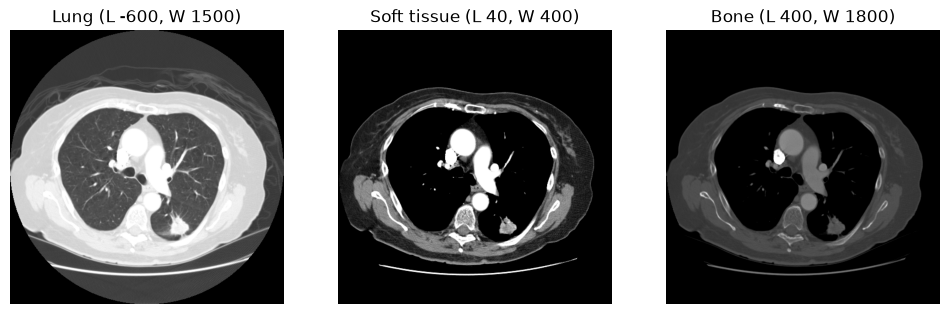

HU range on this slice: -2048 to 3071


In [5]:
# A2. Build the volume in Hounsfield units, then show one slice with three windows
volume = np.stack([pydicom.dcmread(f).pixel_array for f in files]).astype(np.float32)
volume = volume * float(h.RescaleSlope) + float(h.RescaleIntercept)   # stored → HU

def window(img, level, width):
    lo = level - width / 2
    return np.clip((img - lo) / width, 0, 1)

k = 89                                         # the slice through the nodule
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, L, W) in zip(axes, [('Lung', -600, 1500), ('Soft tissue', 40, 400), ('Bone', 400, 1800)]):
    ax.imshow(window(volume[k], L, W), cmap='gray'); ax.set_title(f'{name} (L {L}, W {W})'); ax.axis('off')
plt.show()
print('HU range on this slice:', int(volume[k].min()), 'to', int(volume[k].max()))

### A3. Three planes from one volume
SimpleITK reads a series, sorts it and keeps the spacing, so views in other planes have the right proportions.

Size (512, 512, 133) | spacing (mm) (0.7, 0.7, 2.5)


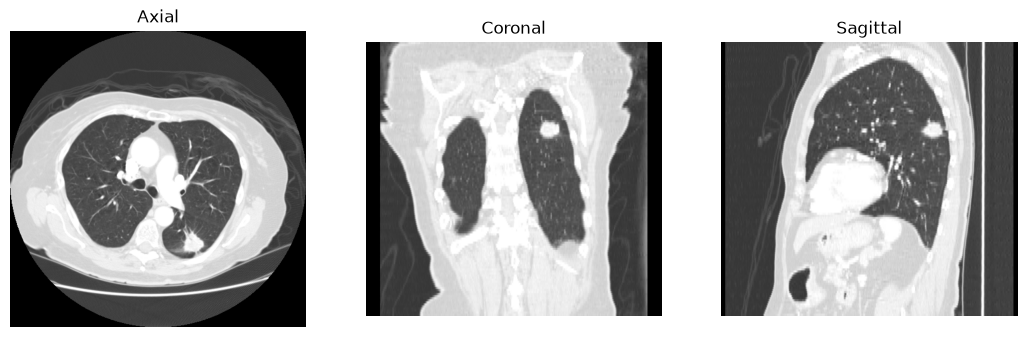

In [6]:
# A3. Let SimpleITK read and sort the series, then cut it three ways
reader = sitk.ImageSeriesReader()
reader.SetFileNames(reader.GetGDCMSeriesFileNames(ct_dir))
ct = reader.Execute()                          # already in HU, with spacing and position
arr = sitk.GetArrayFromImage(ct)               # (z, y, x)
sx, sy, sz = ct.GetSpacing()
print('Size', ct.GetSize(), '| spacing (mm)', tuple(round(s, 2) for s in ct.GetSpacing()))

z, y, x = 89, 367, 316                         # the nodule
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(window(arr[z], -600, 1500), cmap='gray'); axes[0].set_title('Axial')
axes[1].imshow(window(arr[::-1, y, :], -600, 1500), cmap='gray', aspect=sz / sx); axes[1].set_title('Coronal')
axes[2].imshow(window(arr[::-1, :, x], -600, 1500), cmap='gray', aspect=sz / sy); axes[2].set_title('Sagittal')
for ax in axes: ax.axis('off')
plt.show()

In [7]:
# A4. Other modalities, other rules: the same patient's X-ray, and a brain MRI series
dx = pydicom.dcmread(glob.glob(os.path.join(LIDC, 'DX-*', '*.dcm'))[0])
print('X-ray:', dx.Rows, 'x', dx.Columns, '|', dx.BitsStored, 'bits |', dx.PhotometricInterpretation,
      '| window tags', dx.WindowCenter, dx.WindowWidth, '(these look copied from a CT)')
mri_dir = os.path.join(DATA, 'upenn', 't2_Flair_axial')
if os.path.isdir(mri_dir):
    m = pydicom.dcmread(sorted(glob.glob(os.path.join(mri_dir, '*.dcm')))[0], stop_before_pixels=True)
    print('MRI:', m.SeriesDescription, '| slice', m.SliceThickness, 'mm | no Hounsfield units: values are relative')

X-ray: 2022 x 2022 | 14 bits | MONOCHROME2 | window tags -600 1600 (these look copied from a CT)
MRI: t2_Flair_axial: Processed_CaPTk | slice 3 mm | no Hounsfield units: values are relative


## Workflow B — Matching an X-ray with descriptions (BiomedCLIP)

BiomedCLIP turns an image and a sentence into 512 numbers each. Cosine similarity says how well they match.

BiomedCLIP does not read DICOM. We prepare the X-ray ourselves: window to 8 bits, then let the model's own preprocessing resize and normalise it.

In [8]:
# B1. Load BiomedCLIP and prepare our patient's X-ray from DICOM
import open_clip
from PIL import Image

MODEL = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
model, preprocess = open_clip.create_model_from_pretrained(MODEL)
tokenizer = open_clip.get_tokenizer(MODEL)
model = model.to(DEVICE).eval()

px = dx.pixel_array.astype(np.float32)
lo, hi = np.percentile(px, [0.5, 99.5])                  # window: keep 99% of the values
xray = Image.fromarray((np.clip((px - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)).convert('RGB')
image = preprocess(xray).unsqueeze(0).to(DEVICE)        # resize to 224 x 224, normalise
print('Model input:', tuple(image.shape))

Model input: (1, 3, 224, 224)


In [9]:
# B2. Score candidate descriptions by cosine similarity and rank them
candidates = [
    'a normal chest X-ray',
    'a chest X-ray showing an enlarged heart (cardiomegaly)',
    'a chest X-ray showing fluid around the lung (pleural effusion)',
    'a chest X-ray showing a collapsed lung (pneumothorax)',
    'a chest X-ray showing a mass in the lung',
    'an axial CT scan of the chest',
    'an MRI scan of the brain',
]
with torch.no_grad():
    img_emb = torch.nn.functional.normalize(model.encode_image(image), dim=-1)
    txt_emb = torch.nn.functional.normalize(model.encode_text(tokenizer(candidates, context_length=256).to(DEVICE)), dim=-1)
cosine = (img_emb @ txt_emb.T)[0].cpu().numpy()
for i in np.argsort(-cosine):
    print(f'{cosine[i]:.3f}  {candidates[i]}')

0.405  a chest X-ray showing a mass in the lung
0.401  a normal chest X-ray
0.399  a chest X-ray showing fluid around the lung (pleural effusion)
0.376  a chest X-ray showing a collapsed lung (pneumothorax)
0.332  a chest X-ray showing an enlarged heart (cardiomegaly)
0.302  an axial CT scan of the chest
0.227  an MRI scan of the brain


In [10]:
# B3. Why these are not probabilities: softmax with the model's temperature exaggerates tiny gaps
scale = model.logit_scale.exp().item()
p = torch.softmax(torch.tensor(cosine) * scale, 0).numpy()
top2 = np.argsort(-cosine)[:2]
print(f'Cosine gap between the top two: {cosine[top2[0]] - cosine[top2[1]]:.3f}')
print(f'After softmax (x{scale:.0f}): {p[top2[0]]:.2f} vs {p[top2[1]]:.2f}  <- looks confident, is not calibrated')

Cosine gap between the top two: 0.004
After softmax (x85): 0.42 vs 0.29  <- looks confident, is not calibrated


In [11]:
# B4. A failure case: an IU X-ray whose report says "Small bilateral pleural effusions"
iu = os.path.join(DATA, 'iu', 'png', 'CXR2747_IM-1198-1001.png')
if os.path.exists(iu):
    with torch.no_grad():
        e = torch.nn.functional.normalize(model.encode_image(preprocess(Image.open(iu).convert('RGB')).unsqueeze(0).to(DEVICE)), dim=-1)
    c = (e @ txt_emb.T)[0].cpu().numpy()
    for i in np.argsort(-c)[:3]:
        print(f'{c[i]:.3f}  {candidates[i]}')
else:
    print('IU images not downloaded; see README (optional, 1.4 GB).')

0.434  a normal chest X-ray
0.386  a chest X-ray showing a mass in the lung
0.365  a chest X-ray showing fluid around the lung (pleural effusion)


In [12]:
# B5. How long does one image take?
def time_one(device, n=20):
    m = model.to(device)
    x = image.to(device)
    with torch.no_grad():
        m.encode_image(x)                                   # warm-up
        t = time.perf_counter()
        for _ in range(n):
            m.encode_image(x)
        if device == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t) / n

timings = {'cpu_s': round(time_one('cpu', 5), 3)}
if DEVICE == 'cuda':
    timings['gpu_s'] = round(time_one('cuda'), 4)
model = model.to(DEVICE)
print('Seconds per image:', timings)

Seconds per image: {'cpu_s': 0.032, 'gpu_s': 0.0051}


## Workflow C — Outlining anatomy and the nodule

### C1. TotalSegmentator: 117 structures from the CT folder
TotalSegmentator reads the DICOM folder directly. On a GPU this takes about a minute; on a CPU, use `fast=True` and allow several minutes.

lung_lower_lobe_left      736.7 ml
heart                     370.3 ml
aorta                     188.1 ml
liver                    1018.1 ml


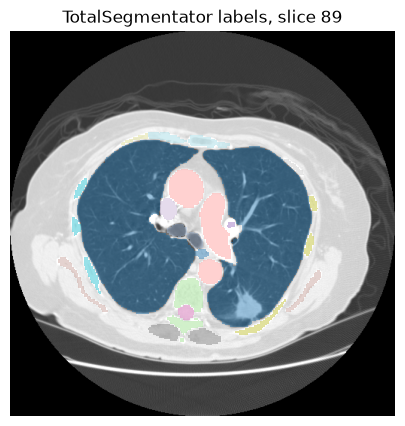

In [13]:
# C1. Run TotalSegmentator (skipped if a result already exists) and overlay a few structures
from totalsegmentator.python_api import totalsegmentator
from totalsegmentator.map_to_binary import class_map

out = 'data/work/ts/total.nii.gz'
if not os.path.exists(out):
    t = time.perf_counter()
    totalsegmentator(ct_dir, out, ml=True, device='gpu' if DEVICE == 'cuda' else 'cpu', fast=DEVICE != 'cuda')
    print(f'TotalSegmentator took {time.perf_counter() - t:.0f} s')
labels = sitk.GetArrayFromImage(sitk.Resample(sitk.ReadImage(out), ct, sitk.Transform(), sitk.sitkNearestNeighbor, 0))
names = class_map['total']
voxel_ml = sx * sy * sz / 1000
for part in ['lung_lower_lobe_left', 'heart', 'aorta', 'liver']:
    i = [k for k, v in names.items() if v == part][0]
    print(f'{part:22s} {np.sum(labels == i) * voxel_ml:8.1f} ml')

plt.figure(figsize=(5, 5))
plt.imshow(window(arr[z], -600, 1500), cmap='gray')
plt.imshow(np.ma.masked_equal(labels[z], 0), cmap='tab20', alpha=0.45, interpolation='nearest')
plt.axis('off'); plt.title('TotalSegmentator labels, slice 89'); plt.show()

In [14]:
# C2. Check against the radiologists: does any label mark the nodule? Where does MedSAM agree?
seg_files = sorted(glob.glob(os.path.join(LIDC, 'SEG-*', '*.dcm')))
readers = []
for f in seg_files:
    s = pydicom.dcmread(f)
    m = np.zeros(arr.shape, bool)
    for fr, plane in zip(np.atleast_3d(s.pixel_array.transpose(1, 2, 0)).transpose(2, 0, 1), s.PerFrameFunctionalGroupsSequence):
        kz = int(round((float(plane.PlanePositionSequence[0].ImagePositionPatient[2]) - ct.GetOrigin()[2]) / sz))
        m[kz] |= fr.astype(bool)
    readers.append(m)
nodule = np.any(readers, axis=0)
lung_ids = [k for k, v in names.items() if v.startswith('lung_')]
print(f'Nodule voxels inside the TotalSegmentator lung label: {np.isin(labels[nodule], lung_ids).mean():.1%}')
print('-> the lung outline swallows the tumour; this model outlines anatomy, not disease')

def dice(a, b): return float(2 * (a & b).sum() / (a.sum() + b.sum()))
print('Radiologist vs radiologist (3D Dice):', [round(dice(readers[0], r), 2) for r in readers[1:]])

Nodule voxels inside the TotalSegmentator lung label: 99.9%
-> the lung outline swallows the tumour; this model outlines anatomy, not disease


Radiologist vs radiologist (3D Dice): [0.84, 0.87, 0.89]


In [15]:
# C3. MedSAM: a box around the nodule on slice 89 -> an outline, compared with each radiologist
from transformers import SamModel, SamProcessor
ys, xs = np.nonzero(nodule[z])
box = [int(xs.min()) - 5, int(ys.min()) - 5, int(xs.max()) + 5, int(ys.max()) + 5]
rgb = np.repeat((window(arr[z], 40, 400) * 255).astype(np.uint8)[..., None], 3, axis=2)
proc = SamProcessor.from_pretrained('wanglab/medsam-vit-base')
sam = SamModel.from_pretrained('wanglab/medsam-vit-base').to(DEVICE).eval()
with torch.no_grad():
    inp = proc(rgb, input_boxes=[[box]], return_tensors='pt').to(DEVICE)
    out_ = sam(**inp, multimask_output=False)
mask = proc.image_processor.post_process_masks(out_.pred_masks.sigmoid().cpu(), inp['original_sizes'].cpu(),
                                               inp['reshaped_input_sizes'].cpu(), binarize=False)[0][0, 0].numpy() > 0.5
print('MedSAM vs each radiologist (Dice on this slice):', [round(dice(mask, r[z]), 2) for r in readers])

Loading weights:   0%|          | 0/315 [00:00<?, ?it/s]

MedSAM vs each radiologist (Dice on this slice): [0.75, 0.76, 0.76, 0.77]


## Workflow D — Real DICOM files from six kinds of scanner

The sample pack in `../public/dicom/` holds small *teaching copies* of real DICOM files from public collections: every original tag kept, private tags removed, pixels downsampled where needed, and the change written into each file's `DerivationDescription`. The same files open in the deck's DICOM viewer slide and can be downloaded from it.

In [16]:
# D1. Open every file and print the tags that matter for each kind of scan
pack = sorted(glob.glob('../public/dicom/*.dcm'))
for f in pack:
    d = pydicom.dcmread(f)
    frames = int(d.get('NumberOfFrames', 1))
    print(f"{os.path.basename(f):28s} {d.Modality:3s} {d.Rows}x{d.Columns}"
          f"{f' x{frames} frames' if frames > 1 else ''}  {d.PhotometricInterpretation:11s} {d.BitsStored}-bit"
          f"  units: {'HU' if d.Modality == 'CT' else d.get('Units', '-')}")
print()
print('Change recorded in one file:', pydicom.dcmread(pack[0]).DerivationDescription)

ct-fdg-lung.dcm              CT  512x512  MONOCHROME2 12-bit  units: HU
ct-lidc-0001.dcm             CT  512x512  MONOCHROME2 16-bit  units: HU
mammo-cmmd-d2-0333.dcm       MG  573x478  MONOCHROME2 8-bit  units: -
mri-flair-upenn-00001.dcm    MR  256x192  MONOCHROME2 16-bit  units: -
pet-fdg-lung.dcm             PT  400x400  MONOCHROME2 16-bit  units: BQML
seg-fdg-lung-slice.dcm       SEG 400x400  MONOCHROME2 1-bit  units: -
seg-lidc-0001-reader1.dcm    SEG 512x512 x8 frames  MONOCHROME2 1-bit  units: -
seg-lidc-0001-reader2.dcm    SEG 512x512 x7 frames  MONOCHROME2 1-bit  units: -
seg-lidc-0001-reader3.dcm    SEG 512x512 x8 frames  MONOCHROME2 1-bit  units: -
seg-lidc-0001-reader4.dcm    SEG 512x512 x9 frames  MONOCHROME2 1-bit  units: -
us-liver-ceus.dcm            US  162x292 x21 frames  RGB         8-bit  units: -
xray-lidc-0001.dcm           DX  505x505  MONOCHROME2 14-bit  units: -

Change recorded in one file: Teaching copy for an FDP slide deck: private tags removed; pixels unc

Mammogram: ImageLaterality = R | ViewPosition = not recorded
Ultrasound: (21, 162, 292, 3) | FrameTime 537.3984 ms | duration 11.3 s


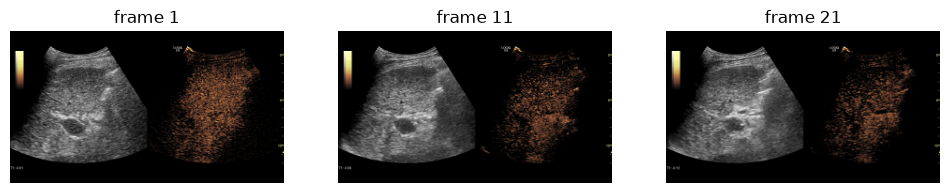

In [17]:
# D2. Modality-specific details: which breast (mammogram), and an ultrasound file is a video
mg = pydicom.dcmread('../public/dicom/mammo-cmmd-d2-0333.dcm')
print('Mammogram: ImageLaterality =', mg.ImageLaterality, '| ViewPosition =', mg.get('ViewPosition', 'not recorded'))
us = pydicom.dcmread('../public/dicom/us-liver-ceus.dcm')
cine = us.pixel_array                                   # (frames, rows, columns, 3): colour video
print('Ultrasound:', cine.shape, '| FrameTime', float(us.FrameTime), 'ms | duration', round(cine.shape[0] * float(us.FrameTime) / 1000, 1), 's')
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, k in zip(axes, [0, cine.shape[0] // 2, cine.shape[0] - 1]):
    ax.imshow(cine[k]); ax.set_title(f'frame {k + 1}'); ax.axis('off')
plt.show()

In [18]:
# D3. PET pixels are Bq/ml; the file's own tags turn them into SUV (body weight, decay-corrected)
pet = pydicom.dcmread('../public/dicom/pet-fdg-lung.dcm')
r = pet.RadiopharmaceuticalInformationSequence[0]
tm = lambda t: int(t[:2]) * 3600 + int(t[2:4]) * 60 + float(t[4:])
minutes = (tm(pet.SeriesTime) - tm(r.RadiopharmaceuticalStartTime)) / 60
dose_now = float(r.RadionuclideTotalDose) * 2 ** (-minutes * 60 / float(r.RadionuclideHalfLife))
suv = pet.pixel_array * float(pet.RescaleSlope) * float(pet.PatientWeight) * 1000 / dose_now
print(f'{r.Radiopharmaceutical}: {float(r.RadionuclideTotalDose) / 1e6:.0f} MBq, scan {minutes:.1f} min later'
      f' -> {dose_now / 1e6:.1f} MBq left; weight {pet.PatientWeight} kg; max SUV on this slice {suv.max():.1f}')

Fluorodeoxyglucose: 300 MBq, scan 60.1 min later -> 205.3 MBq left; weight 61 kg; max SUV on this slice 14.2


Same frame of reference: True | CT 512 px at 0.802734375 mm; PET 400 px at 2.03642 mm


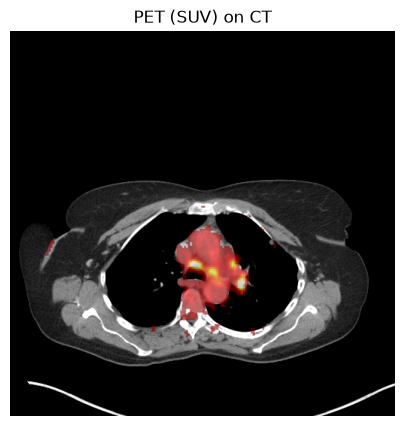

In [19]:
# D4. PET/CT fusion: the PET and CT files share a frame of reference, so their positions line up
ct2 = pydicom.dcmread('../public/dicom/ct-fdg-lung.dcm')
hu2 = ct2.pixel_array * float(ct2.RescaleSlope) + float(ct2.RescaleIntercept)
print('Same frame of reference:', pet.FrameOfReferenceUID == ct2.FrameOfReferenceUID,
      '| CT', ct2.Rows, 'px at', float(ct2.PixelSpacing[0]), 'mm; PET', pet.Rows, 'px at', float(pet.PixelSpacing[0]), 'mm')
# Place both in millimetres and draw PET on top of CT
ext = lambda d: [float(d.ImagePositionPatient[0]), float(d.ImagePositionPatient[0]) + d.Columns * float(d.PixelSpacing[1]),
                 float(d.ImagePositionPatient[1]) + d.Rows * float(d.PixelSpacing[0]), float(d.ImagePositionPatient[1])]
plt.figure(figsize=(5, 5))
plt.imshow(window(hu2, 40, 400), cmap='gray', extent=ext(ct2))
plt.imshow(np.ma.masked_less(suv, 1.5), cmap='hot', vmin=0, vmax=8, alpha=0.6, extent=ext(pet))
plt.xlim(ext(ct2)[:2]); plt.ylim(ext(ct2)[2:]); plt.axis('off'); plt.title('PET (SUV) on CT'); plt.show()

## Workflow E — Analyses and insights from DICOM, in Python

Four short analyses on the sample pack, each ending in one insight. The same code is also written to `dicom_insights.py`, so it runs from a terminal too:

```bash
python dicom_insights.py all        # or: tissue, nodule, pet, audit; figures are saved in figures/
```

In [20]:
# E0. Helpers shared by E1-E4 (also the top of dicom_insights.py)
import os
import numpy as np
import pydicom
import matplotlib.pyplot as plt

PACK = '../public/dicom'
FIG_DIR = None                       # set to a folder to save figures instead of showing them


def load(name):
    return pydicom.dcmread(os.path.join(PACK, name))


def values(ds):
    """Pixel values in the file's real units (rescale slope and intercept applied)."""
    return ds.pixel_array * float(ds.get('RescaleSlope', 1)) + float(ds.get('RescaleIntercept', 0))


def seg_on(seg, img):
    """A DICOM SEG mask placed on one image slice, using both files' positions and orientations."""
    sh = seg.SharedFunctionalGroupsSequence[0]
    sy, sx = (float(v) for v in sh.PixelMeasuresSequence[0].PixelSpacing)
    half = float(sh.PixelMeasuresSequence[0].SliceThickness) / 2
    iop = np.array(sh.PlaneOrientationSequence[0].ImageOrientationPatient, float)
    o, ipp, (py, px) = np.array(img.ImageOrientationPatient, float), np.array(img.ImagePositionPatient, float), (float(v) for v in img.PixelSpacing)
    frames = seg.pixel_array.reshape(-1, seg.Rows, seg.Columns)
    for frame, item in zip(frames, seg.PerFrameFunctionalGroupsSequence):
        pos = np.array(item.PlanePositionSequence[0].ImagePositionPatient, float)
        if abs(pos[2] - ipp[2]) < half:
            r, c = np.mgrid[0:img.Rows, 0:img.Columns]
            p = ipp + c[..., None] * o[:3] * px + r[..., None] * o[3:] * py - pos
            sc, sr = np.rint(p @ iop[:3] / sx).astype(int), np.rint(p @ iop[3:] / sy).astype(int)
            ok = (sr >= 0) & (sr < seg.Rows) & (sc >= 0) & (sc < seg.Columns)
            mask = np.zeros((img.Rows, img.Columns), bool)
            mask[ok] = frame[sr[ok], sc[ok]] > 0
            return mask
    return np.zeros((img.Rows, img.Columns), bool)


def longest(mask, ds):
    """Longest distance (mm) between two pixels of a 2D mask."""
    ys, xs = np.nonzero(mask)
    pts = np.stack([xs * float(ds.PixelSpacing[1]), ys * float(ds.PixelSpacing[0])], 1)
    return float(np.sqrt(((pts[:, None] - pts[None]) ** 2).sum(-1)).max())


def suv_factor(pet):
    """Body-weight SUV per Bq/ml, decay-corrected to series start, from the PET file's tags."""
    r = pet.RadiopharmaceuticalInformationSequence[0]
    tm = lambda t: int(t[:2]) * 3600 + int(t[2:4]) * 60 + float(t[4:])
    dose = float(r.RadionuclideTotalDose) * 2 ** (-(tm(pet.SeriesTime) - tm(r.RadiopharmaceuticalStartTime)) / float(r.RadionuclideHalfLife))
    return float(pet.PatientWeight) * 1000 / dose


def show(fig, name):
    if FIG_DIR:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=120, bbox_inches='tight')
        plt.close(fig)
        print('figure saved:', os.path.join(FIG_DIR, f'{name}.png'))
    else:
        plt.show()

lung           332 cm²
fat            205 cm²
soft tissue    126 cm²
bone            38 cm²
Insight: lung is 47% of the tissue on this slice


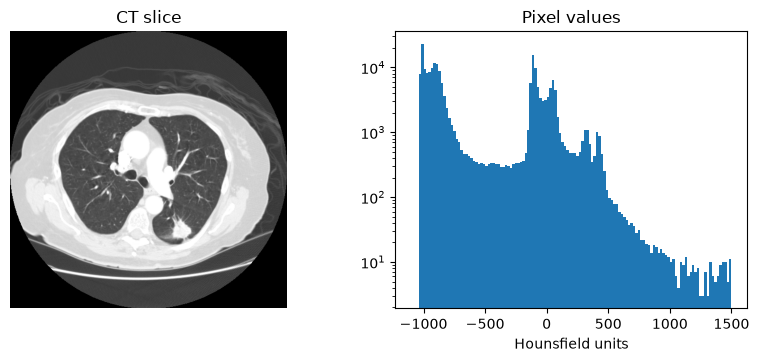

In [21]:
# E1. CT: what tissue is on this slice? Hounsfield units sort the pixels; pixel size gives cm²
ct = load('ct-lidc-0001.dcm')
hu = values(ct)
cm2 = float(ct.PixelSpacing[0]) * float(ct.PixelSpacing[1]) / 100
bands = {'lung': (-950, -500), 'fat': (-150, -30), 'soft tissue': (-30, 100), 'bone': (300, 3000)}
area = {k: ((hu >= lo) & (hu < hi)).sum() * cm2 for k, (lo, hi) in bands.items()}
for k, v in area.items():
    print(f'{k:12s} {v:5.0f} cm²')
print(f"Insight: lung is {100 * area['lung'] / sum(area.values()):.0f}% of the tissue on this slice")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].imshow(np.clip((hu + 1350) / 1500, 0, 1), cmap='gray'); ax[0].set_title('CT slice'); ax[0].axis('off')
ax[1].hist(hu.ravel(), bins=130, range=(-1100, 1500), log=True); ax[1].set_xlabel('Hounsfield units'); ax[1].set_title('Pixel values')
show(fig, 'E1_tissue')

Reader 1: 7.3 cm³, longest 31 mm, mean 5 HU
Reader 2: 5.7 cm³, longest 32 mm, mean 31 HU
Reader 3: 6.1 cm³, longest 30 mm, mean 27 HU
Reader 4: 6.8 cm³, longest 32 mm, mean 28 HU
Insight: same nodule, same images, volumes differ by 28%


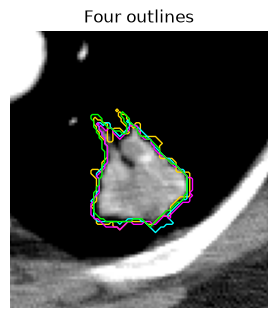

In [22]:
# E2. CT: measure the nodule each of four radiologists outlined (DICOM SEG files)
ct = load('ct-lidc-0001.dcm')
hu = values(ct)
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.imshow(np.clip((hu + 160) / 400, 0, 1), cmap='gray')
volumes = []
for r, colour in zip(range(1, 5), ['gold', 'cyan', 'magenta', 'lime']):
    seg = load(f'seg-lidc-0001-reader{r}.dcm')
    pm = seg.SharedFunctionalGroupsSequence[0].PixelMeasuresSequence[0]
    volumes.append((seg.pixel_array > 0).sum() * float(pm.PixelSpacing[0]) * float(pm.PixelSpacing[1]) * float(pm.SliceThickness) / 1000)
    m = seg_on(seg, ct)
    print(f'Reader {r}: {volumes[-1]:.1f} cm³, longest {longest(m, ct):.0f} mm, mean {hu[m].mean():.0f} HU')
    ax.contour(m, levels=[0.5], colors=colour, linewidths=1)
ys, xs = np.nonzero(m)
ax.set_xlim(xs.min() - 30, xs.max() + 30); ax.set_ylim(ys.max() + 30, ys.min() - 30); ax.axis('off'); ax.set_title('Four outlines')
print(f'Insight: same nodule, same images, volumes differ by {100 * (max(volumes) / min(volumes) - 1):.0f}%')
show(fig, 'E2_nodule')

SUVmax 14.2 | SUVmean 3.4 | area 18.8 cm²
Insight: tumour-to-background ratio 4.3: about 4x more sugar


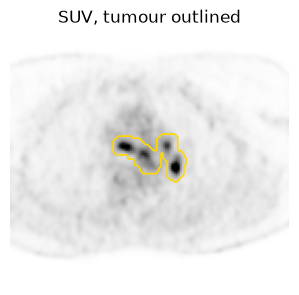

In [23]:
# E3. PET: how hot is the tumour? SUV from the file's own tags; tumour from the expert's DICOM SEG
pet = load('pet-fdg-lung.dcm')
suv = values(pet) * suv_factor(pet)
lesion = seg_on(load('seg-fdg-lung-slice.dcm'), pet)
background = (suv > 0.3) & ~lesion
area = lesion.sum() * float(pet.PixelSpacing[0]) * float(pet.PixelSpacing[1]) / 100
print(f'SUVmax {suv[lesion].max():.1f} | SUVmean {suv[lesion].mean():.1f} | area {area:.1f} cm²')
print(f'Insight: tumour-to-background ratio {suv[lesion].mean() / suv[background].mean():.1f}: about {suv[lesion].mean() / suv[background].mean():.0f}x more sugar')
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.imshow(suv, cmap='gray_r', vmin=0, vmax=8); ax.contour(lesion, levels=[0.5], colors='gold', linewidths=1.2)
ys, xs = np.nonzero(lesion)
ax.set_xlim(xs.min() - 50, xs.max() + 50); ax.set_ylim(ys.max() + 50, ys.min() - 50); ax.axis('off'); ax.set_title('SUV, tumour outlined')
show(fig, 'E3_pet')

In [24]:
# E4. Audit the metadata of every image file in the pack
print(f"{'File':28s}{'Modality':9s}{'Identity removed':17s}{'Birth date':11s}{'Pixel size':14s}Private tags")
missing = 0
files = sorted(f for f in os.listdir(PACK) if f.endswith('.dcm') and not f.startswith('seg-'))
for f in files:
    d = load(f)
    size = d.get('PixelSpacing') or d.get('ImagerPixelSpacing')
    missing += size is None
    private = sum(e.tag.is_private for e in d)
    print(f"{f:28s}{d.Modality:9s}{d.get('PatientIdentityRemoved', 'not stated'):17s}{d.get('PatientBirthDate') or 'empty':11s}"
          f"{(f'{float(size[0]):.3f} mm' if size else 'not recorded'):14s}{private}")
print(f'Insight: {missing} of {len(files)} files record no pixel size, so nothing in them can be measured in mm')

File                        Modality Identity removed Birth date Pixel size    Private tags
ct-fdg-lung.dcm             CT       YES              empty      0.803 mm      0
ct-lidc-0001.dcm            CT       YES              empty      0.703 mm      0
mammo-cmmd-d2-0333.dcm      MG       YES              empty      0.376 mm      0
mri-flair-upenn-00001.dcm   MR       YES              empty      0.938 mm      0
pet-fdg-lung.dcm            PT       YES              empty      2.036 mm      0
us-liver-ceus.dcm           US       YES              empty      not recorded  0
xray-lidc-0001.dcm          DX       YES              empty      not recorded  0
Insight: 2 of 7 files record no pixel size, so nothing in them can be measured in mm


## Interpreting what you saw

* **Cosine scores** rank options for one image. They are not probabilities, and not diagnoses. Small gaps mean the model is unsure.
* **Softmax "probabilities"** from CLIP-style models are not calibrated; do not report them as confidence.
* **Segmentation** is only as good as its purpose: TotalSegmentator outlines anatomy and silently includes the tumour inside "lung".
* **Agreement** between experts is itself imperfect (Dice about 0.84–0.90 here), so a model's Dice must be judged against that.
* **Preparation** choices (window, resize, which series) change results. Write them down.

## Save this run's numbers for the slides

In [25]:
# Record what this run produced, so the slides can show where their numbers came from
os.makedirs('../data/runs', exist_ok=True)
json.dump({'device': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU',
           'biomedclip_seconds_per_image': timings,
           'patient_xray_ranking': {candidates[i]: round(float(cosine[i]), 4) for i in np.argsort(-cosine)},
           'softmax_top2': [round(float(p[top2[0]]), 3), round(float(p[top2[1]]), 3)],
           'medsam_dice_vs_readers': [round(float(dice(mask, rd[z])), 3) for rd in readers],
           'run_date': time.strftime('%Y-%m-%d')},
          open('../data/runs/notebook.json', 'w'), indent=1)
print('saved ../data/runs/notebook.json')

saved ../data/runs/notebook.json
